# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
208,0.030811,-0.044642,0.040140,0.076958,0.017694,0.037830,-0.028674,0.034309,-0.001496,0.119043,155.0
390,0.009016,0.050680,0.069241,0.059744,0.017694,-0.023234,-0.047082,0.034309,0.103297,0.073480,277.0
27,-0.023677,-0.044642,0.059541,-0.040099,-0.042848,-0.043589,0.011824,-0.039493,-0.015999,0.040343,85.0
261,0.048974,-0.044642,-0.041774,0.104501,0.035582,-0.025739,0.177497,-0.076395,-0.012909,0.015491,103.0
365,0.034443,-0.044642,-0.038540,-0.012556,0.009439,0.005262,-0.006584,-0.002592,0.031193,0.098333,206.0
188,0.005383,-0.044642,-0.002973,0.049415,0.074108,0.070710,0.044958,-0.002592,-0.001496,-0.009362,141.0
368,-0.016412,0.050680,0.002417,0.014987,0.021822,-0.010082,-0.024993,0.034309,0.085531,0.081764,123.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
325,-0.001882,-0.044642,0.054152,-0.066506,0.072732,0.056619,-0.043401,0.084863,0.084492,0.048628,192.0
24,-0.063635,-0.044642,0.035829,-0.022885,-0.030464,-0.018850,-0.006584,-0.002592,-0.025953,-0.054925,184.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
# Cuantos valos faltantes hay en cada columna
valores_faltantes = data.isnull().sum()

print("Valores faltantes por columna: ")
print(valores_faltantes)

Valores faltantes por columna: 
age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:
# impución para llenar valores faltantes.
imputer = SimpleImputer(strategy='mean')
data_imputed = pd.DataFrame(imputer.fit_transform(data), columns=data.columns)

print("\nValores faltantes después de la imputación: ")
print(data_imputed.isnull().sum()) 



Valores faltantes después de la imputación: 
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [8]:
# imputación de valores con KNNImputer con columnas "bmi" y "bp"
knn_imputer = KNNImputer(n_neighbors=5)
data_knn_imputed = pd.DataFrame(knn_imputer.fit_transform(data), columns=data.columns)

print("\nValores faltantes después de la imputación con KNN: ")
print(data_knn_imputed.isnull().sum())

# Comparación entre imputación simple y KNN para las columnas con valores faltantes
for col in ['bmi', 'bp']:
    mask = data[col].isna()
    simple_vals = data_imputed.loc[mask, col]
    knn_vals = data_knn_imputed.loc[mask, col]
    diff = np.abs(simple_vals - knn_vals)

    comparison = pd.DataFrame({
        'imputacion_simple': simple_vals.values,
        'knn_imputer': knn_vals.values,
        'diferencia_absoluta': diff.values
    })

    print(f"\nColumna: {col}")
    print(comparison.head())
    print("Diferencia absoluta promedio:", round(diff.mean(), 4))
    print("Diferencia absoluta máxima:", round(diff.max(), 4))


Valores faltantes después de la imputación con KNN: 
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Columna: bmi
   imputacion_simple  knn_imputer  diferencia_absoluta
0          -0.000205     0.072690             0.072895
1          -0.000205     0.007806             0.008010
2          -0.000205    -0.024529             0.024324
3          -0.000205    -0.000601             0.000396
4          -0.000205    -0.021511             0.021306
Diferencia absoluta promedio: 0.0253
Diferencia absoluta máxima: 0.0729

Columna: bp
   imputacion_simple  knn_imputer  diferencia_absoluta
0           0.000465    -0.048589             0.049054
1           0.000465    -0.005443             0.005909
2           0.000465    -0.021046             0.021512
3           0.000465     0.041841             0.041376
4           0.000465    -0.030459             0.030924
Diferencia absoluta promedio: 0.022
Difere

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

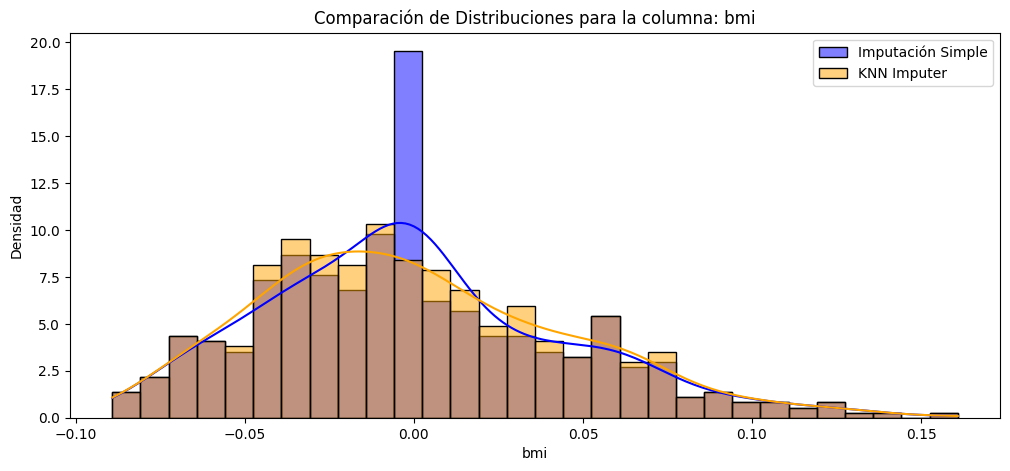

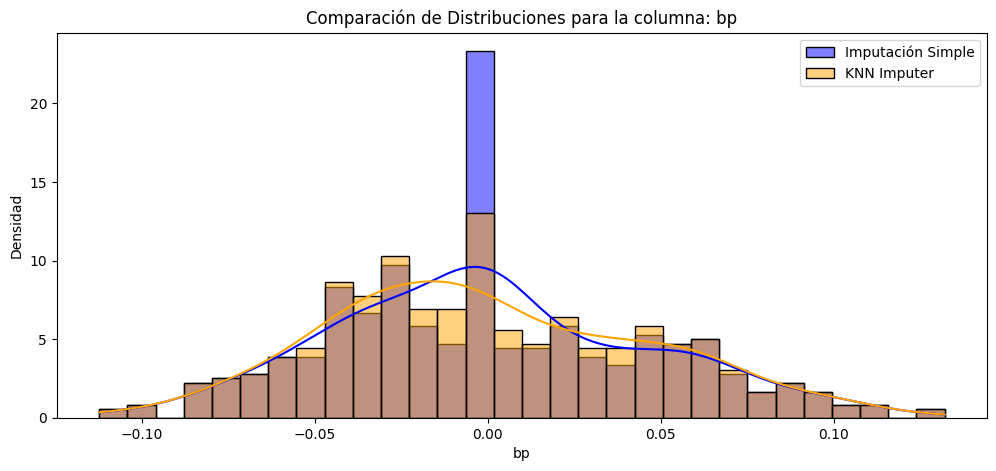

In [9]:
# histograma de comparación entre imputación simple y KNN para las columnas con valores faltantes
for col in ['bmi', 'bp']:
    plt.figure(figsize=(12, 5))
    sns.histplot(data_imputed[col], color='blue', label='Imputación Simple', kde=True, stat="density", bins=30, alpha=0.5)
    sns.histplot(data_knn_imputed[col], color='orange', label='KNN Imputer', kde=True, stat="density", bins=30, alpha=0.5)
    plt.title(f'Comparación de Distribuciones para la columna: {col}')
    plt.xlabel(col)
    plt.ylabel('Densidad')
    plt.legend()
    plt.show() 
    